# Implementation of TMSE-BioCRNpyler Modules: Genetically encoded RNA-based TMSE circuits simulations

**Installing and Initializing Modules**: See [README](https://github.com/usnistgov/TMSE_BioCRNpyler_Library/blob/main/README.md) documentation for additional details.

The following sections highlight important features of the TMSE-BioCRNpyler modules.

Each section illustrate how to compile and simulate a ctRSD circuit, from Design Approaches to Expand the Toolkit for Building Cotranscriptionally Encoded RNA Strand Displacement Circuits ([Schaffter et al. *ACS Synthetic Biology* 2023](https://pubs.acs.org/doi/10.1021/acssynbio.3c00079)), in BioCRNpyler using the TMSE modules. The first code block implements exisiting BioCRNpyler components, mechanisms, and mixtures seemlessly with the TMSE modules to compile a chemcial reaction network (CRN). The CRN is then simulated using BioSCRAPE at various initial conditions in the second code block. 

Specific Features:
* specifying strand exchange molecules from a dictionary directly using `StrandExchangeMol()` enabling transcription and/or RNA maturation
* incorporating RNA maturation using `RNAmaturation()` and leak using `LeakctRSD()`
* using `RNAassembly()` to lever the existing translation mechanism, `SimpleTranslation()`

## Global variables, definitions, and dependencies

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

## Global variables and definitions

In [2]:
# Simulate all models - example for 4 hours
timepoints = np.linspace(0,4,5001)*3600


#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (7, 7)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 22
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs, fontsize=fs)

    plt.ylim(ymin,ymax)
    plt.xlim(0,4)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)
    plt.xticks(np.arange(0, 5, 1))

    # Save plot as svg
    plt.savefig(f'{figs_dir}/main_{fig_name}.svg')

# Genetically encoded RNA-based TMSE circuits simulations

![Genetically encoded RNA-based TMSE circuits](../schematics/Figure2_ctRSD.png)

**Genetically Encoded RNA-based TMSE Circuits Simulation**


In [3]:
# Define initial DNA and Reporter RNA
sim_inputs = {'DNA_1': ['Input', 1]} # Input DNA
sim_gates = {'DNA_2':['Gate',1,2] , 'DNA_GFP':['THErr',2,[None,'GFP']]} # Gate DNA

# Components
step_tx0 =StrandExchangeMol(sim_inputs, transcription=True)
step_tx1 =StrandExchangeMol(sim_gates, material_type = 'dna', transcription=True, 
                            rna_maturation = True, leak = 'ctRSDleak')

step_rz =RNAmaturation(step_tx1)

rna_TMSE = step_tx0.rna + step_tx1.rna + step_rz.rna
step_rsd = TMSE(rna_TMSE)

step_leak = LeakctRSD(step_tx1)

# Reactions
# # Mechanism tx 
mech_tx = SimpleTranscription()
tx_mechanisms = {mech_tx.mechanism_type:mech_tx}
# Mechanism rz
mech_rz = MaturationO1()
rz_mechanisms = {mech_rz.mechanism_type: mech_rz}
# Mechanism strand displacement
mech_rsd = OneStepTMSE()
rsd_mechanisms = {mech_rsd.mechanism_type:mech_rsd}
# Mechanism leak
mech_leak = GateTxLeak()
leak_mechanisms = {mech_leak.mechanism_type:mech_leak}
# Mechanism translation
mech_tl = SimpleTranslation()
tl_mechanisms = {mech_tl.mechanism_type:mech_tl}

# Parameters
ctRSD_parameters = {"ktx": 0.013, "leak_percentage": 0.03, "kmat": 0.00417, 
                    "kx":1e-06, "krev":2.7e-07, "krep":1e4/1e9, "ktl":.0005,} 

# Make Mixture and Compile
M_ctRSD = Mixture("Single_Gate_ctRSD", components=[step_tx0.mol, step_tx1.mol, step_rz, step_rsd, step_rsd.transcripts, step_leak],
             parameters=ctRSD_parameters,
             mechanisms=tx_mechanisms|rz_mechanisms|rsd_mechanisms|leak_mechanisms|tl_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_ctRSD = M_ctRSD.compile_crn()

# Print CRN reactions
print(CRN_ctRSD.pretty_print(show_rates = True, show_attributes = True, 
                       show_materials = True, show_keys = False))

Species(N = 15) = {
rna[THErr_2_nGFP] (@ 0),  rna[THErr_2_nGFP(pre)] (@ 0),  dna[THErr_2_nGFP] (@ 0),  rna[Output_2_nGFP(dummy)] (@ 0),  rna[Output_2] (@ 0),  rna[Output_1_2] (@ 0),  rna[Output_1_2(dummy)] (@ 0),  rna[Input_1] (@ 0),  dna[Input_1] (@ 0),  rna[Gate_1_2] (@ 0),  rna[Gate_1_2(pre)] (@ 0),  dna[Gate_1_2] (@ 0),  rna[GateOut_1_1] (@ 0),  protein[GFP] (@ 0),  rna[GFP] (@ 0),  
}

Reactions (10) = [
0. dna[Input_1] --> dna[Input_1]+rna[Input_1]
 Kf=k_forward * dna_Input_1
  k_forward=0.013

1. dna[Gate_1_2] --> dna[Gate_1_2]+rna[Gate_1_2(pre)]+rna[Output_1_2(dummy)]
 Kf=k_forward * dna_Gate_1_2
  k_forward=0.013

2. dna[THErr_2_nGFP] --> dna[THErr_2_nGFP]+rna[THErr_2_nGFP(pre)]+rna[Output_2_nGFP(dummy)]
 Kf=k_forward * dna_THErr_2_nGFP
  k_forward=0.013

3. rna[Gate_1_2(pre)] --> rna[Gate_1_2]
 Kf=k_forward * rna_Gate_1_2_pre
  k_forward=0.00417

4. rna[THErr_2_nGFP(pre)] --> rna[THErr_2_nGFP]
 Kf=k_forward * rna_THErr_2_nGFP_pre
  k_forward=0.00417

5. rna[Gate_1_2]+rna[Inpu

### Simulated using BioSCRAPE

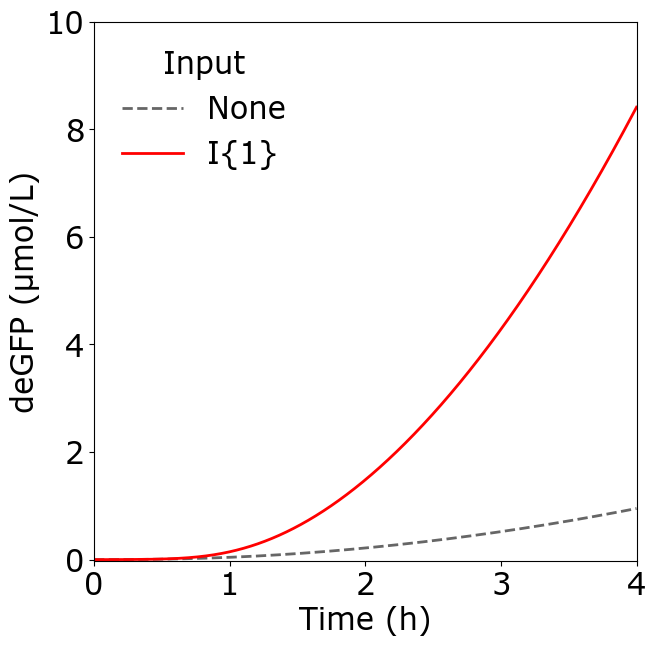

In [4]:
# Simulate
try:
    # Input templates
    IN1 = [0,25]

    idx_conditions = {'None':[[0.4,0.4,0.4], '--'],
                      'I{1}': [[1,0,0],'-'],}

    for I1_conc, key in zip(IN1,idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': I1_conc, 
                                      'dna_Gate_1_2':25, 'dna_THErr_2_nGFP':25}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_ctRSD.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                    initial_condition_dict = initial_concentration_dict)
    
        # Example plotting in the subplots
        plt.plot(R['time']/3600, R['protein_GFP']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='deGFP (μmol/L)',ymax = 10, fig_name= 'Figure2_ctRSD')    

# Computing environment

In [5]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

